# Dødsfall i Norge — per år og måned

Two views of mortality, from two tables:

1. **How many people die, by year and month** — table **14657**
   (*Døde per måned*, 2022M01–2026M06), a stacked bar plus a full month-by-month table.
2. **Long-run context** — table **07902** (*Dødelighetstabeller*, 1966–2025),
   life expectancy at birth.

> **Why two tables.** 07902 is a *life table*: it is annual only, and its `Dode`
> value is a rate **per 100 000 at age x**, not a count of people. It cannot
> answer "how many died in March". 14657 can, so the monthly chart uses it and
> 07902 supplies the long view.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from ssb_statistikkbanken import SSB

pd.set_option("display.max_colwidth", 90)

ssb = SSB()
ssb

SSB(language='no', timeout=30, max_workers=4, cache=True)

## 1 · Find the monthly table

`timeUnit` in the search results is what tells you a table has a month
dimension at all — most SSB tables are annual.

In [2]:
hits = ssb.search("døde per måned", limit=50)
hits.loc[hits["timeUnit"] == "Monthly", ["id", "label", "firstPeriod", "lastPeriod"]]

,id,label,firstPeriod,lastPeriod
0,14657,"14657: Døde per måned, etter kjønn og alder. Foreløpige tall 2022M01-2026M06",2022M01,2026M06
3,08799,"08799: Utenrikshandel med varer, etter varenummer (HS) og land 1988M01-2026M06",1988M01,2026M06
4,11008,"11008: Utenrikshandel med varer, etter varenummer (HS) og handelsområde/verdensdel 198...",1988M01,2026M06


## 2 · Inspect it — `describe()` / `variables()`

Note `Alder` is **not** mandatory. Leaving a non-mandatory variable out makes SSB
aggregate over it, which is how we get all-ages totals without listing 106 codes.

In [3]:
info = ssb.describe("14657")
info

variable,label,values,mandatory,examples
Kjonn,kjønn,3,,0: Begge kjønn; 2: Kvinner; 1: Menn
Alder,alder,106,,000: 0 år; 001: 1 år; 002: 2 år; 003: 3 år; … (+102)
ContentsCode,statistikkvariabel,1,yes,Dode: Døde
Tid,måned,54,yes,2022M01: 2022M01; 2022M02: 2022M02; 2022M03: 2022M03; 2022M04: 2022M04; … (+50)


In [4]:
ssb.variables("14657")

,variable,label,n_values,mandatory,code_lists,example_values
0,Kjonn,kjønn,3,False,,0: Begge kjønn; 2: Kvinner; 1: Menn
1,Alder,alder,106,False,"agg_FemAarigGruppering, agg_TiAarigGruppering, agg_TodeltGrupperingB, agg_TredeltGrupp...",000: 0 år; 001: 1 år; 002: 2 år; …
2,ContentsCode,statistikkvariabel,1,True,,Dode: Døde
3,Tid,måned,54,True,,2022M01: 2022M01; 2022M02: 2022M02; 2022M03: 2022M03; …


## 3 · Fetch — one call

`Kjonn="0"` is both sexes; `Alder` is omitted so SSB sums every age; `time="*"`
takes all 54 months. Because the period codes are `2022M01`-style, the wrapper
derives a real `date` column — that is what makes the month arithmetic below
trivial.

In [5]:
df = ssb.fetch("14657", Kjonn="0", time="*")
df[["Tid", "Tid_code", "date", "value"]].head()

,Tid,Tid_code,date,value
0,2022M01,2022M01,2022-01-01,3950
1,2022M02,2022M02,2022-02-01,3684
2,2022M03,2022M03,2022-03-01,4285
3,2022M04,2022M04,2022-04-01,3773
4,2022M05,2022M05,2022-05-01,3571


In [6]:
print(df.dtypes.to_string())
print(f"\nrows: {len(df)}   {df['Tid_code'].min()} - {df['Tid_code'].max()}")

Kjonn                           str
Kjonn_code                      str
ContentsCode                    str
ContentsCode_code               str
Tid                             str
Tid_code                        str
date                 datetime64[us]
value                         Int64

rows: 54   2022M01 - 2026M06


`date` is a real `datetime64` and `value` a nullable `Int64` — no parsing, no
`.str.split()`. For a monthly table the wrapper emits `date` rather than `year`,
so pull the parts off it directly.

## 4 · Reshape to a year × month grid

In [7]:
df["År"] = df["date"].dt.year
df["Måned"] = df["date"].dt.month

grid = df.pivot_table(index="År", columns="Måned", values="value", aggfunc="sum")
grid.columns = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "Mai",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Okt",
    "Nov",
    "Des",
][: len(grid.columns)]
grid

,Jan,Feb,Mar,Apr,Mai,Jun,Jul,Aug,Sep,Okt,Nov,Des
År,,,,,,,,,,,,
2022,3950,3684,4285,3773,3571,3563,3740,3546,3513,3750,3797,4553
2023,4430,3360,3718,3492,3407,3411,3374,3336,3499,3645,3959,4138
2024,4264,3606,3730,3439,3540,3434,3454,3599,3553,3826,3706,4069
2025,4121,3597,4063,3538,3613,3487,3639,3659,3514,3833,3710,4229
2026,4309,3795,4014,3619,3662,3404,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


### ⚠️ 2026 is incomplete

The series ends at **2026M06**, so 2026 holds six months. Stacking a half-year
next to full years would make the bar look like a collapse in mortality, which
would be nonsense. Count the months rather than assuming:

In [8]:
months_present = grid.notna().sum(axis=1)
print(months_present.to_string())

full_years = months_present[months_present == 12].index
partial = months_present[months_present < 12].index.tolist()
print(f"\nfull years: {list(full_years)}   excluded as partial: {partial}")

År
2022    12
2023    12
2024    12
2025    12
2026     6

full years: [2022, 2023, 2024, 2025]   excluded as partial: [2026]


## 5 · The chart

**Design notes** — 12 months is past the ~8-series ceiling where categorical
colors stop being tellable apart, so this is *not* 12 arbitrary hues. Months are
an **ordered** scale, so they get a **sequential single-hue ramp**: light January
→ dark December. The ramp is stepped to be evenly spaced in perceptual lightness
(OKLab), so no two adjacent months collapse into each other.

The blue anchors on the palette used in the nursing-home notebook, and its red
(`#e61414`) is kept for the annual totals — the same roles as there: blue carries
the data, red marks the figure to read first.

Exact per-month numbers live in the table in section 6 — that is the honest place
for 12 classes, rather than asking color to carry them.

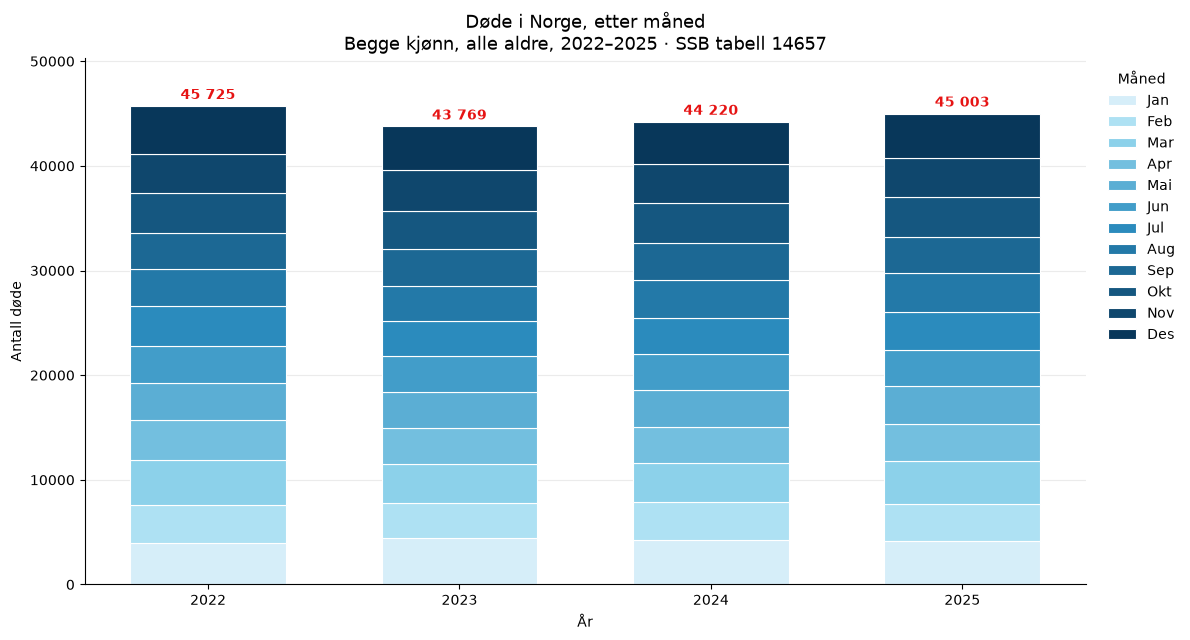

In [9]:
MONTHS = list(grid.columns)
BLUE_RAMP = [
    "#d6eef9",
    "#aee1f3",
    "#8cd1ea",
    "#73bfdf",
    "#5baed4",
    "#429dc9",
    "#2b8bbd",
    "#2379a8",
    "#1c6894",
    "#155780",
    "#0f476d",
    "#08375a",
]
ACCENT = "#e61414"

plot = grid.loc[full_years]
totals = plot.sum(axis=1)

fig, ax = plt.subplots(figsize=(12, 6.5))
bottom = np.zeros(len(plot))
for month, color in zip(MONTHS, BLUE_RAMP, strict=True):
    values = plot[month].to_numpy(dtype=float)
    ax.bar(
        plot.index,
        values,
        width=0.62,
        bottom=bottom,
        label=month,
        color=color,
        edgecolor="white",
        linewidth=0.8,
    )
    bottom += values

for year, total in totals.items():
    ax.annotate(
        f"{int(total):,}".replace(",", " "),
        (year, total),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=ACCENT,
    )

ax.set_title(
    "Døde i Norge, etter måned\n"
    f"Begge kjønn, alle aldre, {plot.index.min()}–{plot.index.max()} · SSB tabell 14657",
    fontsize=13,
)
ax.set_xlabel("År")
ax.set_ylabel("Antall døde")
ax.set_xticks(list(plot.index))
ax.set_ylim(0, totals.max() * 1.10)
ax.legend(title="Måned", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 6 · The table

Where the colors run out. Same palette as the chart, shaded by value so the
seasonal pattern is visible without needing the legend — January and December
consistently heaviest, high summer lightest.

In [10]:
table = grid.copy()
table["Totalt"] = table.sum(axis=1)
table.loc["Snitt"] = table.loc[full_years].mean().round(0)

styled = (
    table.style.format(lambda v: "" if pd.isna(v) else f"{int(v):,}".replace(",", " "))
    .background_gradient(
        cmap=LinearSegmentedColormap.from_list("m", BLUE_RAMP),
        subset=(list(full_years), MONTHS),
        axis=None,
    )
    .set_caption("Døde per måned · SSB tabell 14657 · blank = ikke publisert ennå")
)
styled

,Jan,Feb,Mar,Apr,Mai,Jun,Jul,Aug,Sep,Okt,Nov,Des,Totalt
År,,,,,,,,,,,,,
2022,3 950,3 684,4 285,3 773,3 571,3 563,3 740,3 546,3 513,3 750,3 797,4 553,45 725
2023,4 430,3 360,3 718,3 492,3 407,3 411,3 374,3 336,3 499,3 645,3 959,4 138,43 769
2024,4 264,3 606,3 730,3 439,3 540,3 434,3 454,3 599,3 553,3 826,3 706,4 069,44 220
2025,4 121,3 597,4 063,3 538,3 613,3 487,3 639,3 659,3 514,3 833,3 710,4 229,45 003
2026,4 309,3 795,4 014,3 619,3 662,3 404,,,,,,,22 803
Snitt,4 191,3 562,3 949,3 560,3 533,3 474,3 552,3 535,3 520,3 764,3 793,4 247,44 679


Reading across a row gives the shape of a year; reading down a column compares
the same month across years. Both are things the stacked bar cannot show, which
is exactly why the table is here rather than more colors.

## 7 · Seasonality

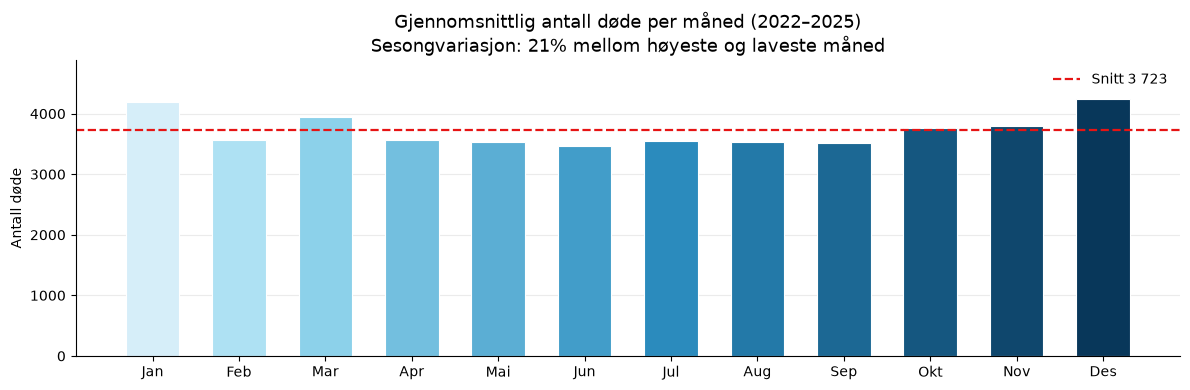

In [11]:
seasonal = grid.loc[full_years].mean()
swing = (seasonal.max() - seasonal.min()) / seasonal.mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(
    seasonal.index,
    seasonal.to_numpy(dtype=float),
    width=0.62,
    color=BLUE_RAMP,
    edgecolor="white",
    linewidth=0.8,
)
ax.axhline(
    seasonal.mean(),
    color=ACCENT,
    linewidth=1.6,
    linestyle="--",
    label=f"Snitt {seasonal.mean():,.0f}".replace(",", " "),
)

ax.set_title(
    f"Gjennomsnittlig antall døde per måned ({plot.index.min()}–{plot.index.max()})\n"
    f"Sesongvariasjon: {swing:.0f}% mellom høyeste og laveste måned",
    fontsize=13,
)
ax.set_ylabel("Antall døde")
ax.set_ylim(0, seasonal.max() * 1.15)
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 8 · Long-run context — table 07902

The life table can't count deaths per month, but it answers the question the
monthly chart raises: mortality is broadly flat year to year, so is anything
changing? Life expectancy at birth over 60 years says yes.

In [12]:
life = ssb.fetch("07902", Kjonn=["1", "2"], AlderX="000", contents="ForvGjenLevetid", time="*")
expectancy = life.pivot_table(index="year", columns="Kjonn", values="value")
expectancy.tail(3)

Kjonn,Kvinner,Menn
year,,
2023,84.63,81.39
2024,84.8,81.59
2025,84.85,81.61


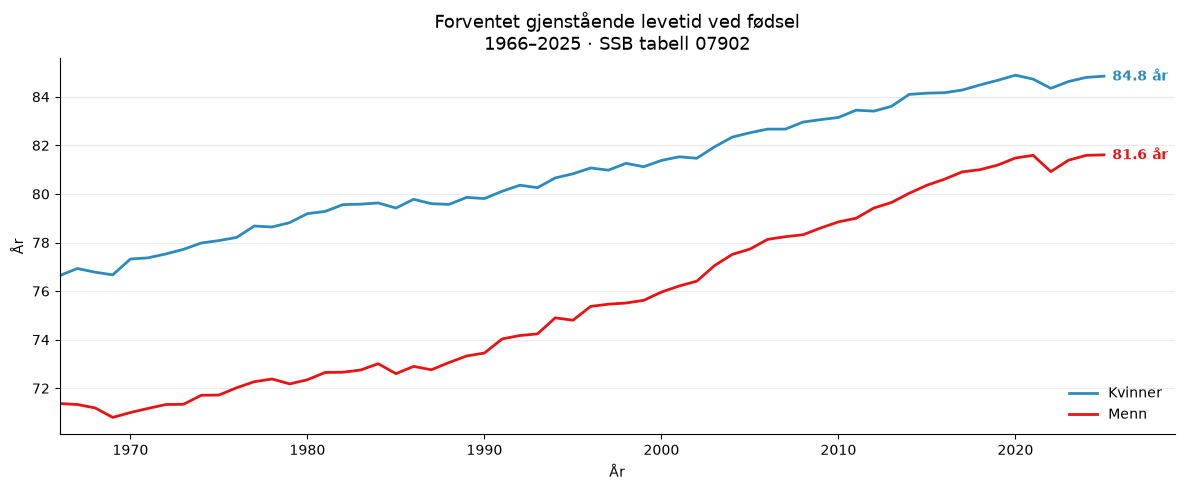

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
for sex, color in zip(expectancy.columns, ["#2b8bbd", ACCENT], strict=True):
    ax.plot(expectancy.index, expectancy[sex], linewidth=2, label=sex, color=color)
    ax.annotate(
        f"{expectancy[sex].iloc[-1]:.1f} år",
        (expectancy.index[-1], expectancy[sex].iloc[-1]),
        textcoords="offset points",
        xytext=(6, 0),
        va="center",
        fontsize=10,
        fontweight="bold",
        color=color,
    )

ax.set_title(
    "Forventet gjenstående levetid ved fødsel\n"
    f"{expectancy.index.min()}–{expectancy.index.max()} · SSB tabell 07902",
    fontsize=13,
)
ax.set_xlabel("År")
ax.set_ylabel("År")
ax.set_xlim(expectancy.index.min(), expectancy.index.max() + 4)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [14]:
gain = (expectancy.iloc[-1] - expectancy.iloc[0]).round(1)
gain.name = f"Økning {expectancy.index.min()}-{expectancy.index.max()} (år)"
gain.to_frame()

,Økning 1966-2025 (år)
Kjonn,
Kvinner,8.2
Menn,10.2


Two series here, not twelve, so this one gets categorical color — the same blue
and red, one per sex, direct-labelled at the line ends so the legend is a
convenience rather than a decoder ring.

The gap between women and men has narrowed by roughly two years since 1966: men
gained more.

---

Cheat sheet: [`list-of-parameters-and-commands.md`](../list-of-parameters-and-commands.md) ·
reference: [`src/README.md`](../src/README.md)